# Vježba 4: *Zadatak za samostalan rad*


> Drazen Baric

In [1]:
import numpy as np
import random
import matplotlib.pyplot as plt
import tensorflow as tf


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.2.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/Users/drazenbaric/Library/Python/3.12/lib/python/site-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/Users/drazenbaric/Library/Python/3.12/lib/python/site-packages/traitlets/config/application.py", line 1075, in launch_instance
    app.start()
  File "/Users/drazenbaric/Library/Python/3.12/lib/python/site-packages/ipykernel/kernelapp.py", line 739, in start
    self

AttributeError: _ARRAY_API not found

## Zadatci
<br>

1. Promijenite način inicijalizacije težina tako da se za inicijalizaciju težina koriste navedene inicijalizacije:

   **(a)** jedinična normalna distribucija $X\sim \mathcal{N}(0,1)$

   **(b)** normalna distribucija $X\sim \mathcal{N}(0,\frac{1}{n_{in}})$ (**LeCun** normalna inicijalizacija).

   Nacrtajte graf koji će prikazivati kako se točnost mijenja za vrijeme treniranja; na istom grafu prikažite krivulje točnosti za He normalnu inicijalizaciju i inicijalizacije **a** i **b**.

<br>

2. „Na ruke” izračunajte predviđanja neuronske mreže trenirane koristeći biblioteku **Keras** za sve primjere iz skupa za testiranje. Izračunajte točnost klasifikacije i usporedite je s rezultatom dobivenim metodom `evaluate`.

#### Priprema
> mreža "from scratch" i podaci

In [2]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def sigmoid_derivacija(z):
    return sigmoid(z) * (1 - sigmoid(z))

class CrossEntropyCost:
    @staticmethod
    def fn(a, y):
        return np.sum(np.nan_to_num(-y*np.log(a)-(1-y)*np.log(1-a)))

    @staticmethod
    def delta(z, a, y):
        return (a-y)

class Network:
    def __init__(self, sizes, init='he', cost=CrossEntropyCost):
        self.num_layers = len(sizes)
        self.sizes = sizes
        self.cost = cost
        scale = {'he': lambda x: np.sqrt(2/x),
                 'normal': lambda x: 1.0,
                 'lecun': lambda x: np.sqrt(1/x)}[init]
        self.biases = [np.random.randn(y, 1) for y in sizes[1:]]
        self.weights = [np.random.randn(y, x) * scale(x)
                        for x, y in zip(sizes[:-1], sizes[1:])]

    def feedforward(self, a):
        for b, w in zip(self.biases, self.weights):
            a = sigmoid(np.dot(w, a) + b)
        return a

    def evaluate(self, data):
        results = [(np.argmax(self.feedforward(x)), np.argmax(y)) for (x, y) in data]
        return sum(int(x == y) for (x, y) in results)

    def fit(self, training_data, epochs, mini_batch_size, eta, test_data):
        n = len(training_data)
        history = []
        for epoch in range(epochs):
            random.shuffle(training_data)
            mini_batches = [training_data[k:k+mini_batch_size] for k in range(0, n, mini_batch_size)]
            for mini_batch in mini_batches:
                self.SGD_update(mini_batch, eta)
            acc = self.evaluate(test_data) / len(test_data)
            history.append(acc)
            print('epoha {0}: accuracy testiranje {1:.2f}%'.format(epoch + 1, 100.0 * acc))
        return history

    def SGD_update(self, mini_batch, eta):
        nabla_b = [np.zeros(b.shape) for b in self.biases]
        nabla_w = [np.zeros(w.shape) for w in self.weights]
        for x, y in mini_batch:
            delta_nabla_b, delta_nabla_w = self.backprop(x, y)
            nabla_b = [nb + dnb for nb, dnb in zip(nabla_b, delta_nabla_b)]
            nabla_w = [nw + dnw for nw, dnw in zip(nabla_w, delta_nabla_w)]
        self.weights = [w - (eta / len(mini_batch)) * nw for w, nw in zip(self.weights, nabla_w)]
        self.biases = [b - (eta / len(mini_batch)) * nb for b, nb in zip(self.biases, nabla_b)]

    def backprop(self, x, y):
        nabla_b = [np.zeros(b.shape) for b in self.biases]
        nabla_w = [np.zeros(w.shape) for w in self.weights]
        activation = x
        activations = [x]
        zs = []
        for b, w in zip(self.biases, self.weights):
            z = np.dot(w, activation) + b
            zs.append(z)
            activation = sigmoid(z)
            activations.append(activation)
        delta = self.cost.delta(zs[-1], activations[-1], y) * sigmoid_derivacija(zs[-1])
        nabla_b[-1] = delta
        nabla_w[-1] = np.dot(delta, activations[-2].transpose())
        for l in range(2, self.num_layers):
            z = zs[-l]
            sp = sigmoid_derivacija(z)
            delta = np.dot(self.weights[-l+1].transpose(), delta) * sp
            nabla_b[-l] = delta
            nabla_w[-l] = np.dot(delta, activations[-l-1].transpose())
        return (nabla_b, nabla_w)

def one_hot(labela):
    x = np.zeros((10, 1))
    x[labela] = 1.0
    return x

In [3]:
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

In [4]:
train_data = [(np.reshape(x, (28*28, 1)), one_hot(y)) for x, y in zip(X_train, y_train)]
test_data = [(np.reshape(x, (28*28, 1)), one_hot(y)) for x, y in zip(X_test, y_test)]

In [5]:
epochs = 15
mini_batch_size = 64
learning_rate = 1.0

#### Rješenje 1.
> usporedba inicijalizacija težina

In [6]:
np.random.seed(7)
random.seed(7)
histories = {}
for init in ['he', 'normal', 'lecun']:
    print('\ninicijalizacija:', init)
    mreza = Network([784, 30, 10], init=init)
    histories[init] = mreza.fit(train_data, epochs, mini_batch_size, learning_rate, test_data)


inicijalizacija: he


epoha 1: accuracy testiranje 90.63%


epoha 2: accuracy testiranje 92.03%


epoha 3: accuracy testiranje 93.05%


epoha 4: accuracy testiranje 93.51%


epoha 5: accuracy testiranje 93.68%


... (36 outputs left out)

epoha 12: accuracy testiranje 94.88%


epoha 13: accuracy testiranje 94.90%


epoha 14: accuracy testiranje 95.13%


epoha 15: accuracy testiranje 95.16%


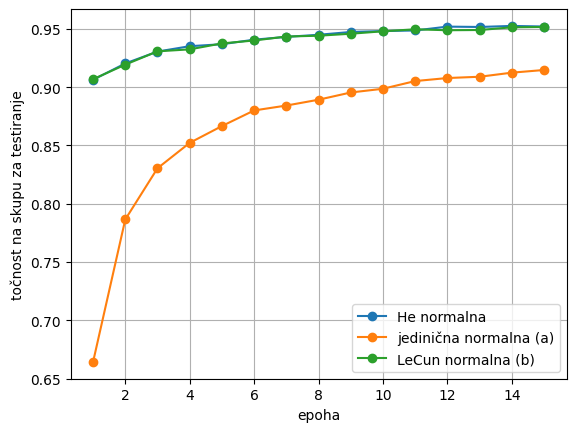

In [7]:
labels = {'he': 'He normalna', 'normal': 'jedinična normalna (a)', 'lecun': 'LeCun normalna (b)'}
for init, h in histories.items():
    plt.plot(range(1, epochs + 1), h, marker='o', label=labels[init])
plt.xlabel('epoha')
plt.ylabel('točnost na skupu za testiranje')
plt.legend()
plt.grid(True)
plt.show()

#### Rješenje 2.
> predviđanja Keras mreže "na ruke"

In [8]:
tf.keras.utils.set_random_seed(7)
model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(30, activation='sigmoid',
                          kernel_initializer=tf.keras.initializers.HeNormal(seed=7),
                          bias_initializer=tf.keras.initializers.RandomNormal(mean=0.0, stddev=1.0, seed=7)),
    tf.keras.layers.Dense(10, activation='sigmoid',
                          kernel_initializer=tf.keras.initializers.HeNormal(seed=7),
                          bias_initializer=tf.keras.initializers.RandomNormal(mean=0.0, stddev=1.0, seed=7))
])
model.compile(loss='categorical_crossentropy',
              optimizer=tf.keras.optimizers.SGD(learning_rate=learning_rate),
              metrics=['accuracy'])

In [9]:
y_train_oh = tf.keras.utils.to_categorical(y_train)
y_test_oh = tf.keras.utils.to_categorical(y_test)
model.fit(X_train, y_train_oh, epochs=epochs, batch_size=mini_batch_size, validation_data=(X_test, y_test_oh))

Epoch 1/15


  1/938 ━━━━━━━━━━━━━━━━━━━━ 2:40 171ms/step - accuracy: 0.0625 - loss: 2.8553

147/938 ━━━━━━━━━━━━━━━━━━━━ 0s 344us/step - accuracy: 0.6417 - loss: 1.2171  

293/938 ━━━━━━━━━━━━━━━━━━━━ 0s 344us/step - accuracy: 0.7297 - loss: 0.9324

442/938 ━━━━━━━━━━━━━━━━━━━━ 0s 341us/step - accuracy: 0.7713 - loss: 0.7924

589/938 ━━━━━━━━━━━━━━━━━━━━ 0s 341us/step - accuracy: 0.7962 - loss: 0.7068

... (128 outputs left out)

547/938 ━━━━━━━━━━━━━━━━━━━━ 0s 367us/step - accuracy: 0.9817 - loss: 0.0650

692/938 ━━━━━━━━━━━━━━━━━━━━ 0s 363us/step - accuracy: 0.9821 - loss: 0.0641

832/938 ━━━━━━━━━━━━━━━━━━━━ 0s 362us/step - accuracy: 0.9823 - loss: 0.0636

938/938 ━━━━━━━━━━━━━━━━━━━━ 0s 443us/step - accuracy: 0.9837 - loss: 0.0596 - val_accuracy: 0.9647 - val_loss: 0.1212


In [10]:
_, keras_acc = model.evaluate(X_test, y_test_oh, verbose=0)
print('evaluate: {:.2f}%'.format(100.0 * keras_acc))

evaluate: 96.47%


In [11]:
W1, b1, W2, b2 = model.get_weights()
A = X_test.reshape(len(X_test), -1)
A = sigmoid(A @ W1 + b1)
A = sigmoid(A @ W2 + b2)
manual_acc = np.mean(A.argmax(axis=1) == y_test)
print('na ruke: {:.2f}%'.format(100.0 * manual_acc))
print('razlika: {:.2e}'.format(abs(manual_acc - keras_acc)))

na ruke: 96.47%
razlika: 1.64e-08
